# Tabulated Chemistry Model:
Triple flame is a methane-air flame configuration that occurs during a combustion process and is characterized by three distinct flame regions. It has a parabolic profile divided into three regions with lean premixed on the top, non-premixed in the middle, and rich premixed on the bottom. The objective of simulating a triple flame using the tabulated chemistry with varying `Z` is to
- reduce the computational time by using the FLUT Tables,
- and to observe the reactants and behavior at different flame configurations.

As mentioned in the earlier used cases to setup a case using the tabulated chemistry the following are needed,
- `0` directory to specify the boundary conditions.
- `constant` directory contains files that remain constant throughout the simulation, such as mesh information, and physical properties.
- `system` control files such as controDict, fvschemes, and fvsolutions that dictate how the simulation is run, including the time-stepping scheme, convergence criteria, and solver settings.

**Note: Along with the above, `FLUT.h5` and `FLUT.bin` files are needed. The `FLUTs` contain the precomputed `flamelet tables`, during the simulation the results are obtained by interpolating the values to the closest value in the tables.**

![image.png](../Figures/tf/tf6.png)

**NOTE: If there is temperature rise(combustion) at the begining then take the `internalFieldValue` of PV as 0.1.**

## Constant Directory
### `blockMeshDict`

![image.png](../Figures/tf/tf7.png)


__The `blockMeshDict`__
- it provides the information about the geometry dimensions and the vertices for the patch allocation as in the above For example for the patch fuel the vertices (0 4 7 3) were taken.

## System Directory
### `controlDict`

- provides all the information about the the solver `rhoFlameletULFFoam` and the simulation parameters like the `start time`, `end time`, `time step` and a dimentionless quantity Courant number `maxCo`

## FLUTs
The creation of FLUTS is already discussed in the `DiffusionFlut Tutorial`
For Triple_Flame,
changes from diffusion_tutorial to triple_flame
- in the input_diffuison.yml file the `chist` values are changed from logspace to list as to accommodate larger values of `chist`.

**parameters:**

    chist:     
    method: list   
    values: [0.1,0.16681005,0.27825594,0.46415888,0.77426368, 1.29154967,2.15443469,3.59381366,5.9948425,10, 30,40,50,60,70,80,90,100]    
    



## Pre-Processing
For the pre-processing Paraview can be used or can be viewed using python as below.


In [1]:
import pyFLUT

#read h5 flut
flut = pyFLUT.Flut.read_hdf5('/WORK_OF/agundeti/123TF/FLUT.h5')
flut


Variable      Min    Max    N
----------  -----  -----  ---
stepPV_1        0   1     101
Mean1           0   0.42  428

In [2]:
import pyvista as pv
import pandas as pd

#read open foam results for TC case
reader = pv.POpenFOAMReader('/WORK_OF/skota/tabtfc1stp0.5/foam_1.foam')
reader.case_type='decomposed'

#times at which results are available 
times = reader.time_values

#chose results at latest time
reader.set_active_time_value(times[-1])
fields = reader.read()['internalMesh']

#write results into a data frame
df = pd.DataFrame(data={field:list(fields[field]) for field in fields.array_names})
df

,p,CH4,CO,CO2,H2O,N2,O2,OH,PV,PVIndex,T,U,Z,noSpecies,omegaPV,rho
0,100000.0,0.000000,0.000000,0.000000,0.000000,0.767091,0.232909,0.000000e+00,1.283170e-35,0.000000,300.000000,"[0.550053, -0.000367885, 0.0]",2.786730e-36,0.0,0.000000,1.171970
1,100000.0,0.000000,0.000000,0.000000,0.000000,0.767091,0.232909,0.000000e+00,1.145580e-34,0.000000,300.000000,"[0.550252, -0.000908551, 0.0]",2.487500e-35,0.0,0.000000,1.171970
2,100000.0,0.000000,0.000000,0.000000,0.000000,0.767091,0.232909,0.000000e+00,4.872450e-34,0.000000,300.000000,"[0.550556, -0.00153166, 0.0]",1.057580e-34,0.0,0.000000,1.171970
3,100000.0,0.000000,0.000000,0.000000,0.000000,0.767091,0.232909,0.000000e+00,1.734070e-33,0.000000,300.000000,"[0.550938, -0.00222759, 0.0]",3.761570e-34,0.0,0.000000,1.171970
4,100000.0,0.000000,0.000000,0.000000,0.000000,0.767091,0.232909,0.000000e+00,5.667650e-33,0.000000,300.000000,"[0.551382, -0.00298786, 0.0]",1.228430e-33,0.0,0.000000,1.171970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,100000.0,0.218036,0.011467,0.009831,0.020086,0.591071,0.147558,1.992730e-07,4.178930e-02,0.174810,525.312988,"[0.841876, -0.065206, 0.0]",2.294640e-01,0.0,0.411015,0.561390
29996,100000.0,0.217682,0.011609,0.009953,0.020334,0.591234,0.147213,2.026270e-07,4.230590e-02,0.176922,528.151978,"[0.84626, -0.0657021, 0.0]",2.292520e-01,0.0,0.415962,0.558387
29997,100000.0,0.217332,0.011749,0.010073,0.020581,0.591395,0.146870,2.059690e-07,4.281870e-02,0.179018,530.969971,"[0.850688, -0.0661038, 0.0]",2.290420e-01,0.0,0.420878,0.555407
29998,100000.0,0.216995,0.011885,0.010190,0.020819,0.591549,0.146538,2.092170e-07,4.331540e-02,0.181047,533.700989,"[0.855012, -0.0663865, 0.0]",2.288410e-01,0.0,0.425577,0.552590


In [3]:
import pyvista as pv
from matplotlib import pyplot as plt

In [4]:
reader = pv.POpenFOAMReader('/WORK_OF/skota/tabtfc1stp0.5/foam_1.foam')
reader.case_type = 'decomposed'
reader.set_active_time_value (0.5)
fields = reader.read()['internalMesh']
fields

UnstructuredGrid (0x7f20edfbf700)
  N Cells:    30000
  N Points:   64840
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   0.000e+00, 1.500e-02
  Z Bounds:   -1.000e-02, 1.000e-02
  N Arrays:   32

In [5]:
line = fields.sample_over_line((0.005,0,0),(0.005,0.015,0),resolution=1000) 
line

PolyData (0x7f20ee042aa0)
  N Cells:    1
  N Points:   1001
  N Strips:   0
  X Bounds:   5.000e-03, 5.000e-03
  Y Bounds:   0.000e+00, 1.500e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   21

In [6]:
print(line.points)
print(line.points[:,1])

[[5.0000e-03 0.0000e+00 0.0000e+00]
 [5.0000e-03 1.5000e-05 0.0000e+00]
 [5.0000e-03 3.0000e-05 0.0000e+00]
 ...
 [5.0000e-03 1.4970e-02 0.0000e+00]
 [5.0000e-03 1.4985e-02 0.0000e+00]
 [5.0000e-03 1.5000e-02 0.0000e+00]]
[0.0000e+00 1.5000e-05 3.0000e-05 ... 1.4970e-02 1.4985e-02 1.5000e-02]


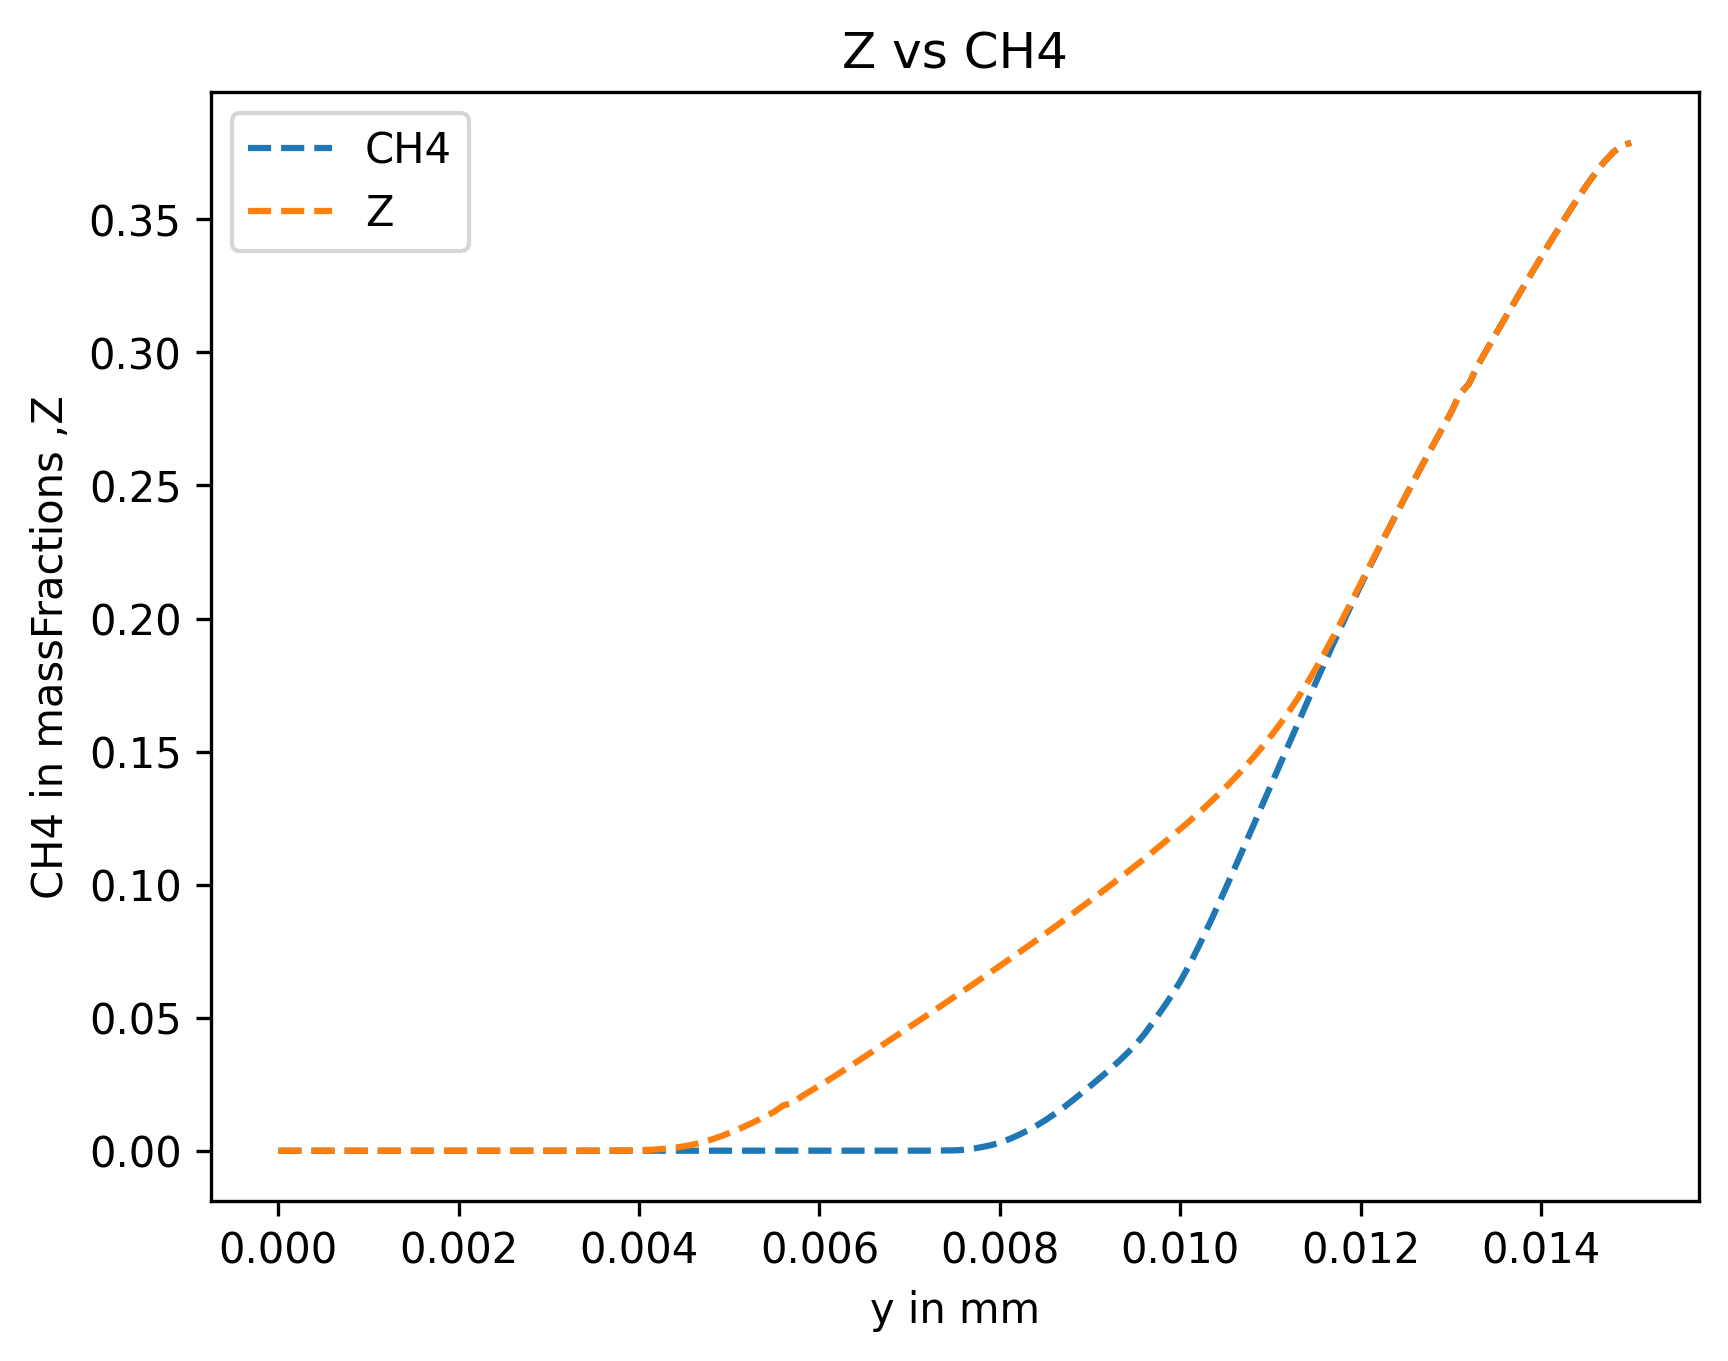

In [7]:
fig, ax = plt.subplots()
fig.set_dpi(300)


ax.plot(line.points[:,1],line['CH4'],label='CH4',linestyle='--')
ax.plot(line.points[:,1],line['Z'],label='Z',linestyle='--')


ax.set_xlabel('y in mm')
ax.set_ylabel('CH4 in massFractions ,Z')
ax.set_title('Z vs CH4')

ax.legend()

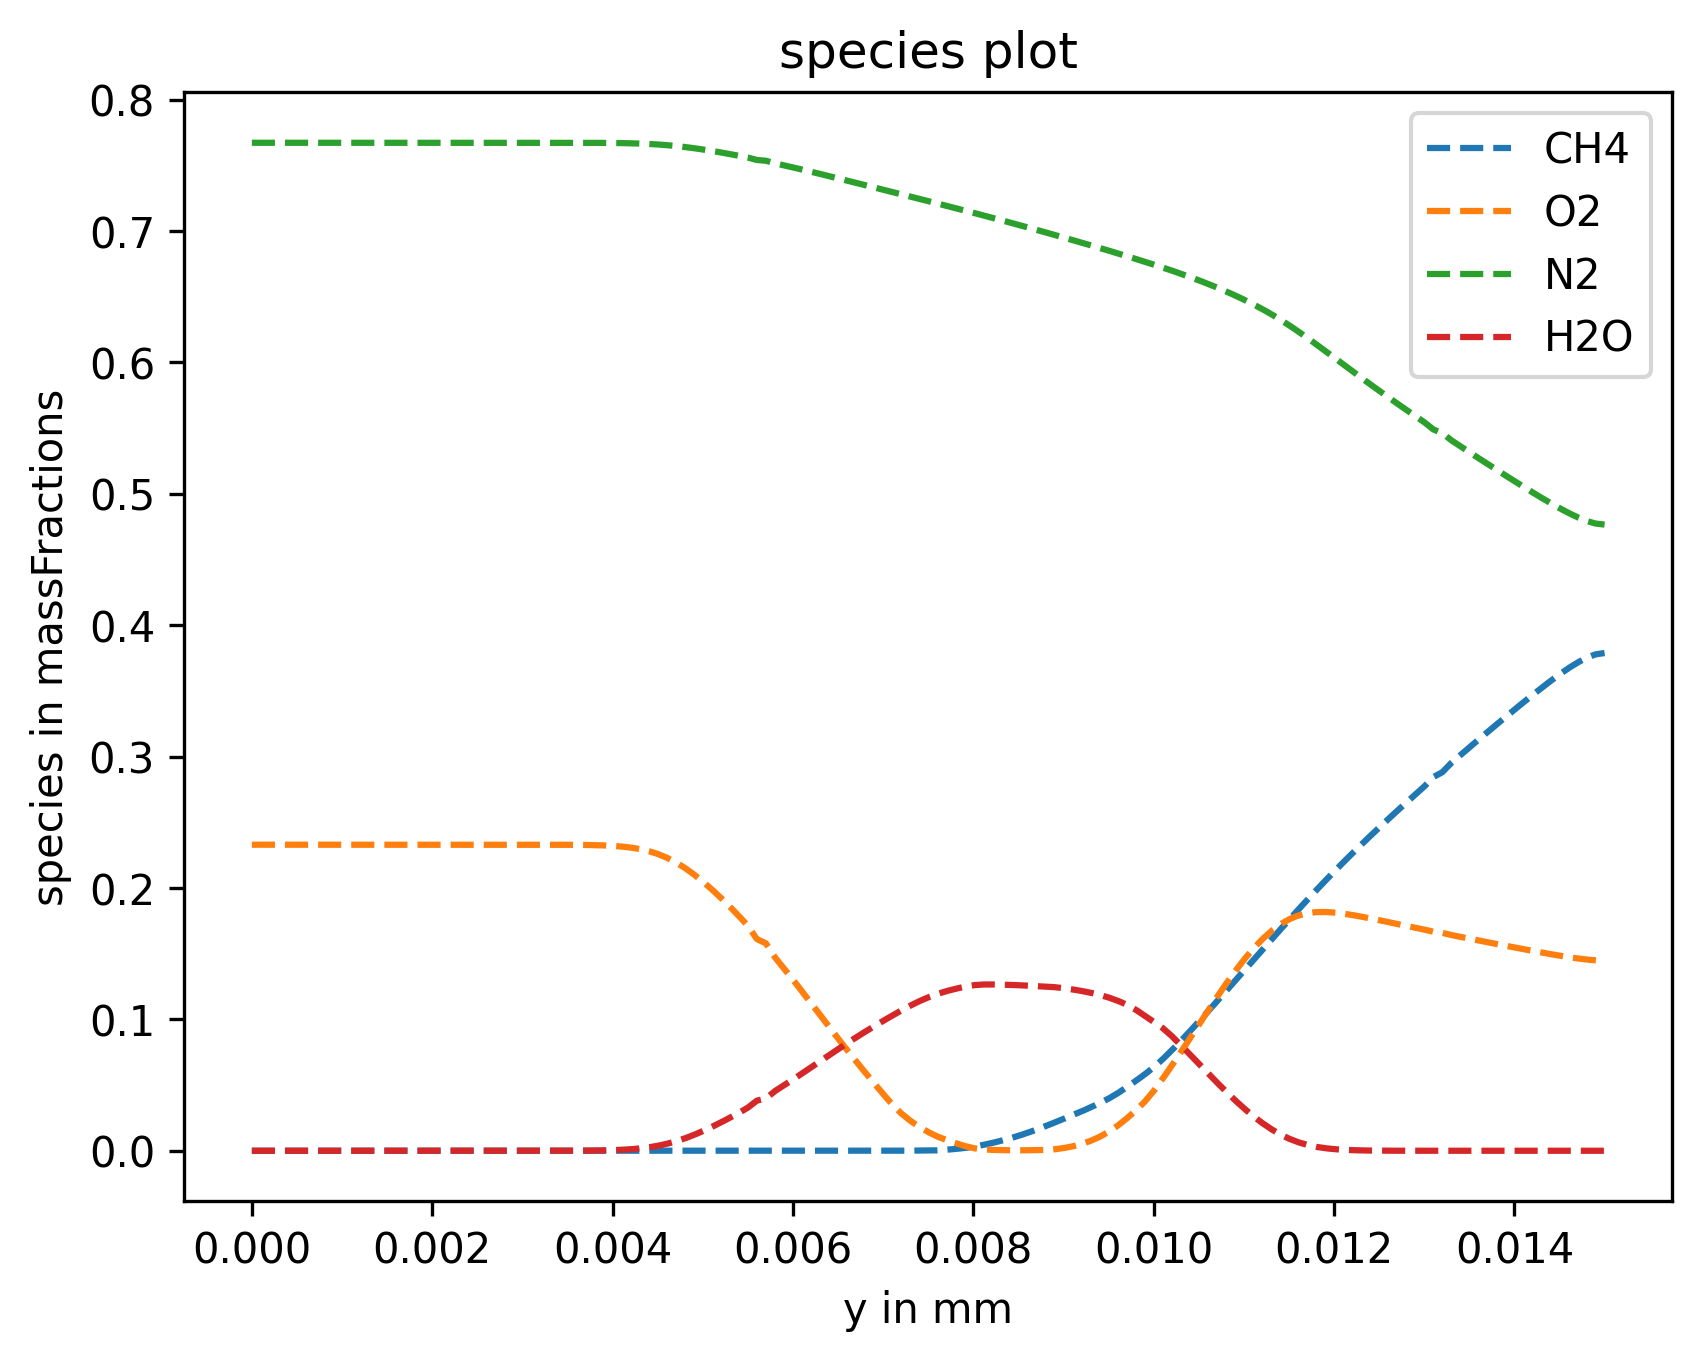

In [8]:
fig, ax = plt.subplots()
fig.set_dpi(300)


ax.plot(line.points[:,1],line['CH4'],label='CH4',linestyle='--')
ax.plot(line.points[:,1],line['O2'],label='O2',linestyle='--')
ax.plot(line.points[:,1],line['N2'],label='N2',linestyle='--')
ax.plot(line.points[:,1],line['H2O'],label='H2O',linestyle='--')
ax.set_xlabel('y in mm')
ax.set_ylabel('species in massFractions')
ax.set_title('species plot')

ax.legend()

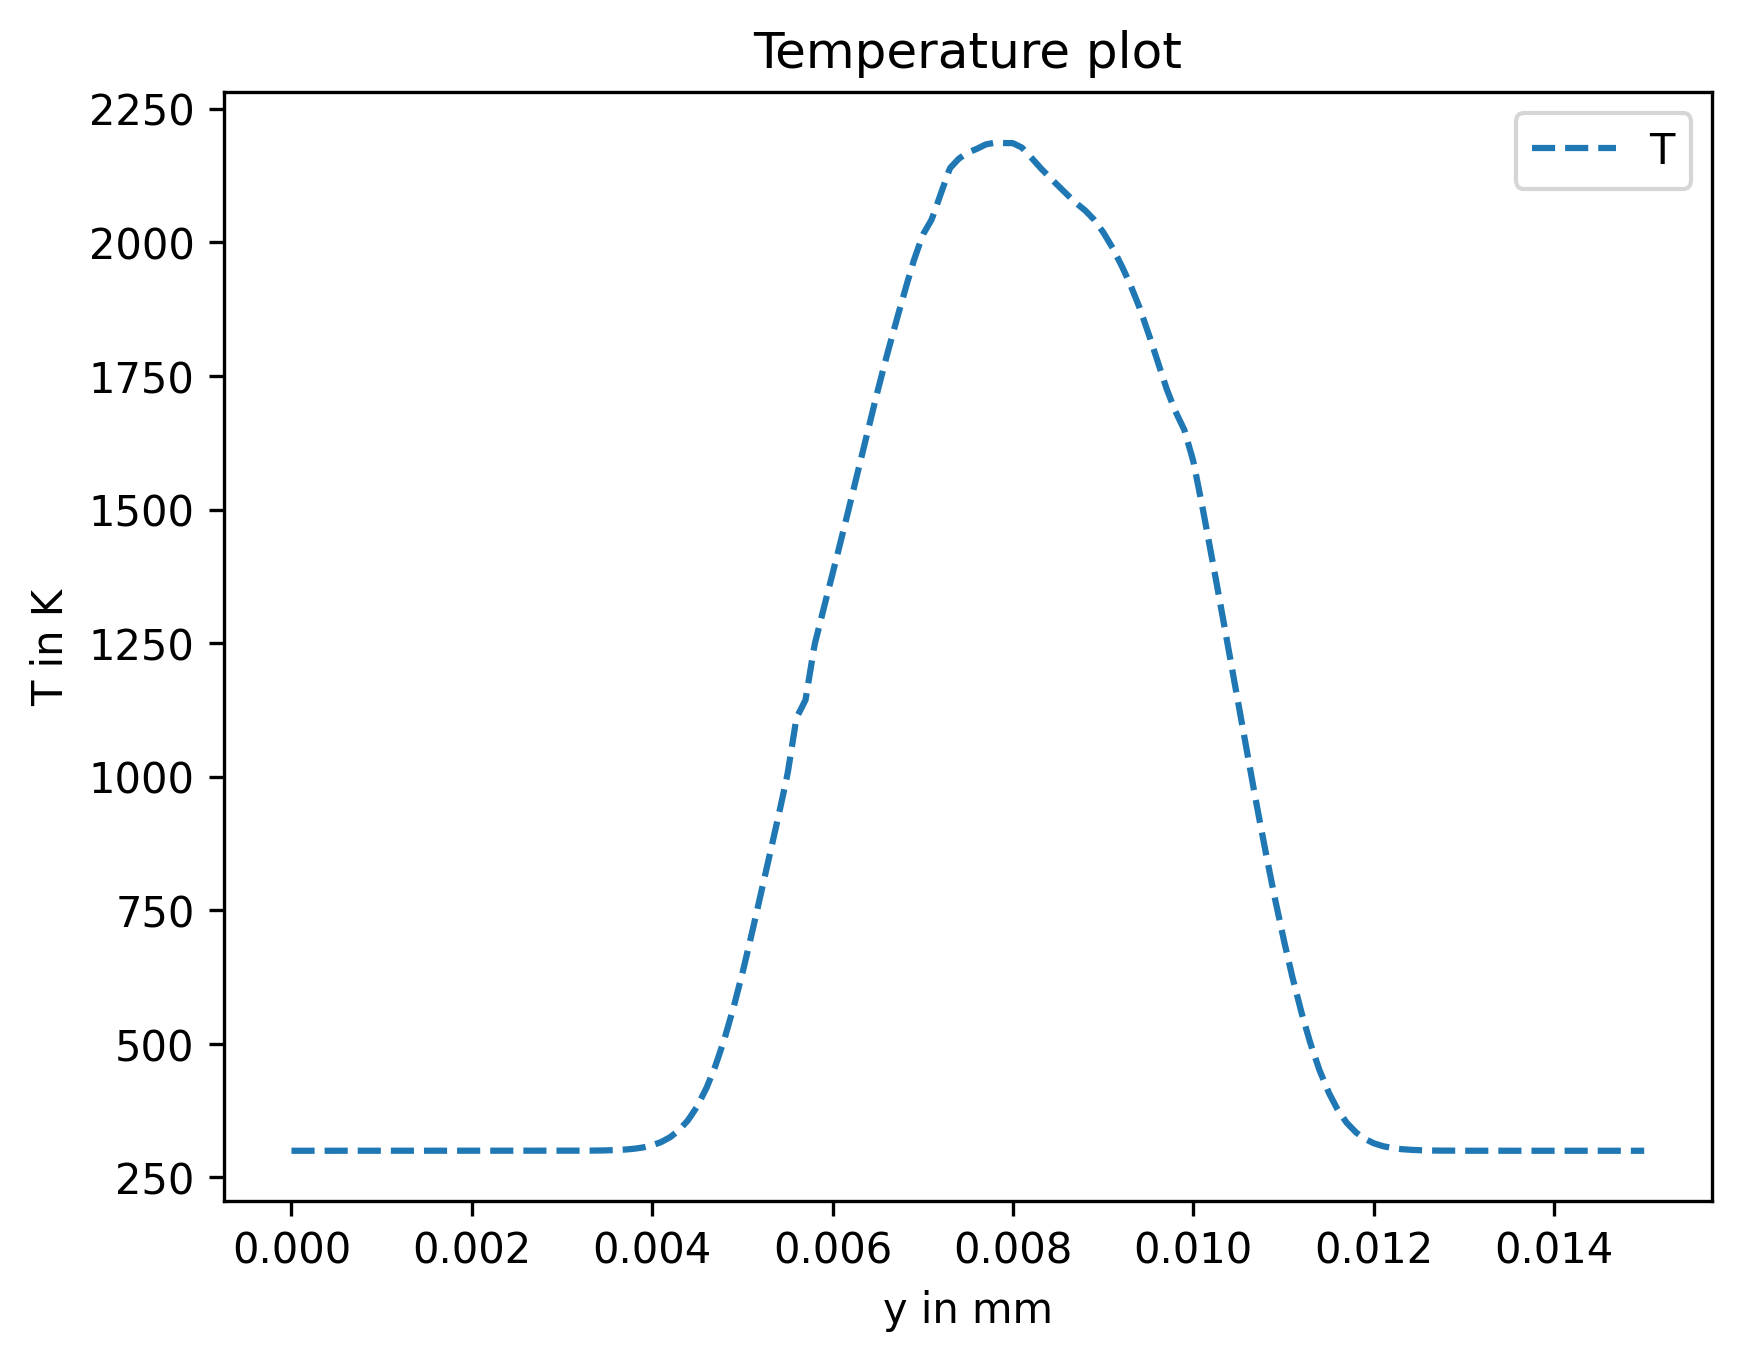

In [9]:
fig, ax = plt.subplots()
fig.set_dpi(300)


ax.plot(line.points[:,1],line['T'],label='T',linestyle='--')


ax.set_xlabel('y in mm')
ax.set_ylabel('T in K')
ax.set_title('Temperature plot')

ax.legend()

In [10]:
slice = fields.slice((0,0,1),(0,0,0)) # origin vector, normal vector
slice

PolyData (0x7f20ee041c60)
  N Cells:    30000
  N Points:   30351
  N Strips:   0
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   0.000e+00, 1.500e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   32

/tmp/ipykernel_5392/3388364775.py:13: UserWarning: The following kwargs were not used by contour: 'triangles'
  tricont = ax.tricontourf(pts[:, 0], pts[:, 1],


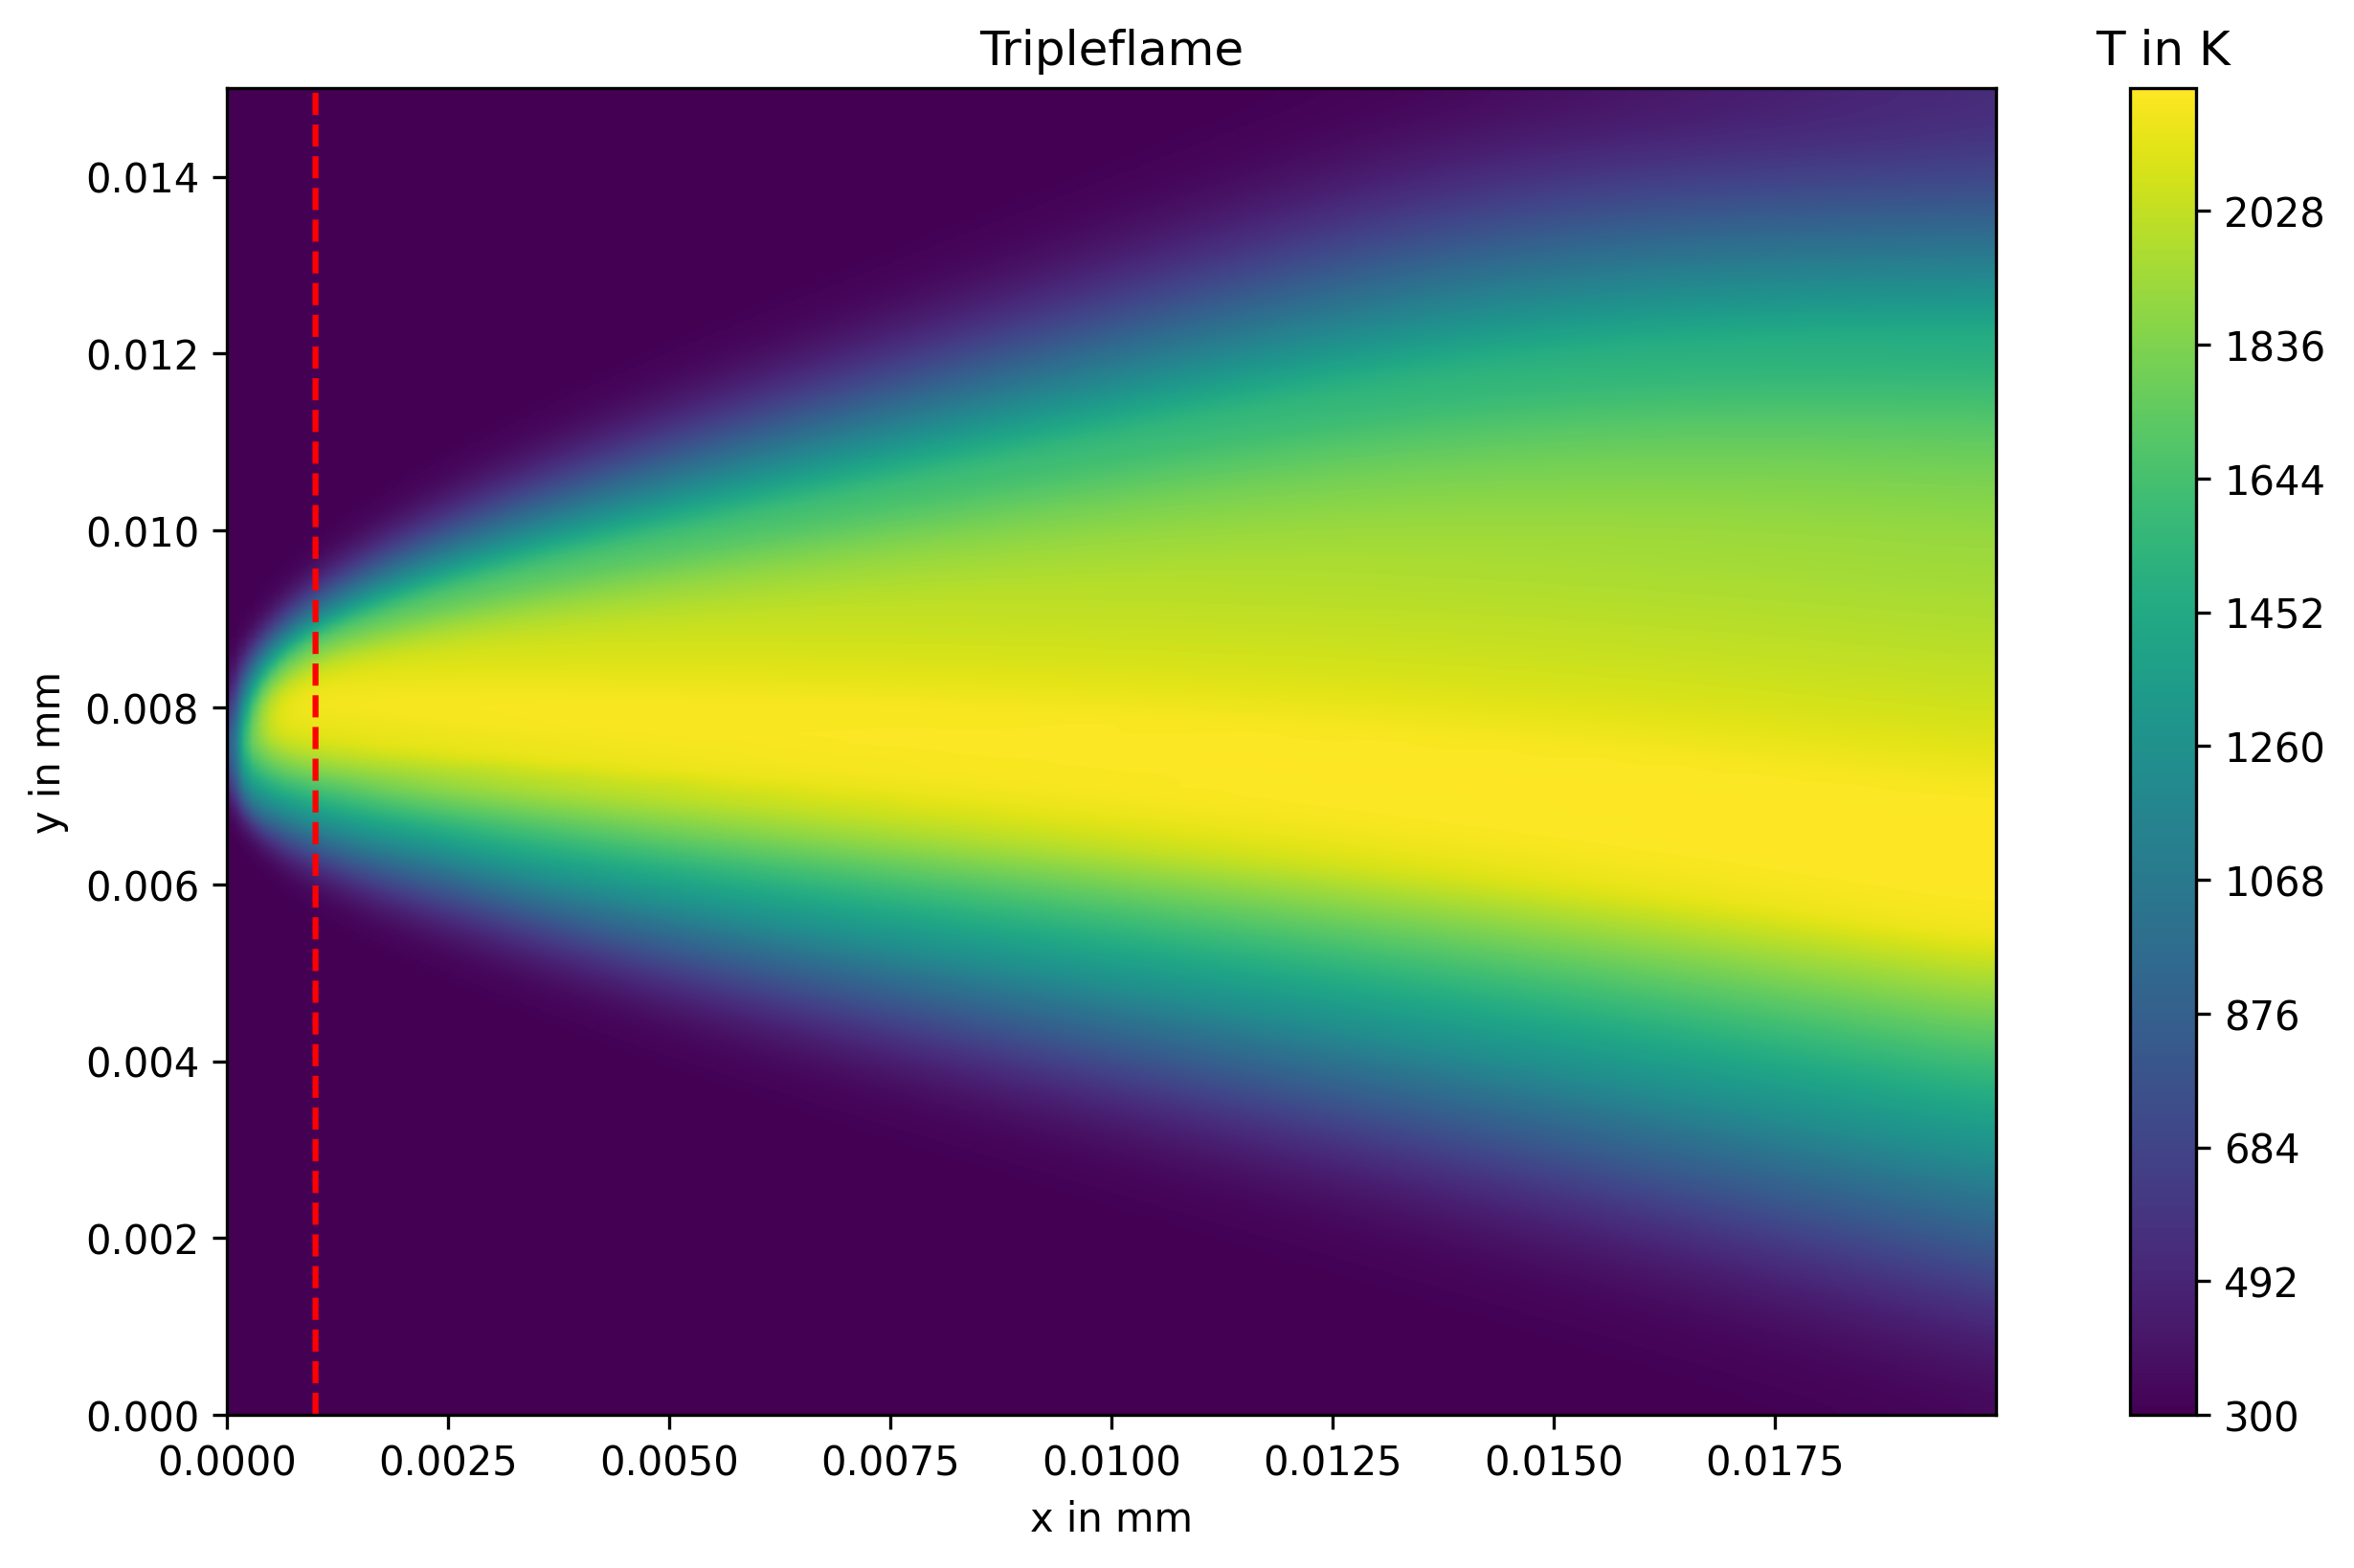

In [18]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=1080)
fig.set_dpi(300)

plt_slice = slice.cell_data_to_point_data()
plt_slice = plt_slice.triangulate()

pts = plt_slice.points
tri = plt_slice.faces.reshape((-1, 4))[:, 1:]

# Pick the field you want to plot (e.g., Temperature T)
val = plt_slice['T']

tricont = ax.tricontourf(pts[:, 0], pts[:, 1],
                        val,
                        triangles=tri,
                        levels=1000,
                        )
ax.set_aspect('equal')
ax.set_xlabel('x in mm')
ax.set_ylabel('y in mm')
ax.set_title('Tripleflame')
cb = fig.colorbar(tricont)
cb.ax.set_title(label='T in K')

# Add the line sample
line = fields.sample_over_line((0.001, 0, 0), (0.001, 0.015, 0))
ax.plot(line.points[:, 0], line.points[:, 1], color='red', markersize=0.25, linestyle='--')
plt.show()
